## Análise e Limpeza de Dados do Google Play Store

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import re
import seaborn as sns


# 1. Carregar o arquivo CSV original
file_path = "googleplaystore.csv"
data = pd.read_csv(file_path, quotechar='"')

# Exibir o número inicial de linhas
total_rows_initial = len(data)
print(f"Número inicial de linhas: {total_rows_initial}")


# 2. Limpeza inicial - Manter o registro com o maior número de 'Reviews' para cada 'App'
data['Reviews'] = pd.to_numeric(data['Reviews'], errors='coerce')  # Converter 'Reviews' para numérico
data = data.sort_values(by='Reviews', ascending=False)  # Ordenar pela maior quantidade de 'Reviews'
data = data.drop_duplicates(subset=['App', 'Category'], keep='first')  # Remover duplicatas com base apenas em 'App'

def clean_app_name(name):
    # Remover emojis utilizando expressão regular
    # Mantém apóstrofo, ponto, vírgula e hífen
    name = re.sub(r"[^\w\s,.'-]", '', name)  # Mantém apóstrofo, ponto, vírgula e hífen
    # Remover aspas duplas
    name = name.replace('"', '')  # Remover todas as aspas duplas
    # Garantir que não haja espaços extras
    name = name.strip()
    return name


# Garantir que a coluna 'App' não tenha espaços extras e fazer a limpeza
data['App'] = data['App'].str.strip().apply(clean_app_name)

# Exibir o número de linhas após a limpeza inicial
total_rows_cleaned = len(data)
print(f"Número de linhas após remover duplicatas: {total_rows_cleaned}")

# Salvar o DataFrame limpo
output_path = "googleplaystore_cleaned.csv"
data.to_csv(output_path, index=False)
print(f"Arquivo limpo salvo em: {output_path}")

# 4. Recarregar os dados limpos para análise
cleaned_file_path = "googleplaystore_cleaned.csv"
data = pd.read_csv(cleaned_file_path)

# Exibir o número de linhas após a limpeza
print(f"Número de linhas nos dados limpos: {len(data)}")

Número inicial de linhas: 10841
Número de linhas após remover duplicatas: 9745
Arquivo limpo salvo em: googleplaystore_cleaned.csv
Número de linhas nos dados limpos: 9745


## 1. Top 5 Apps por Número de Instalações

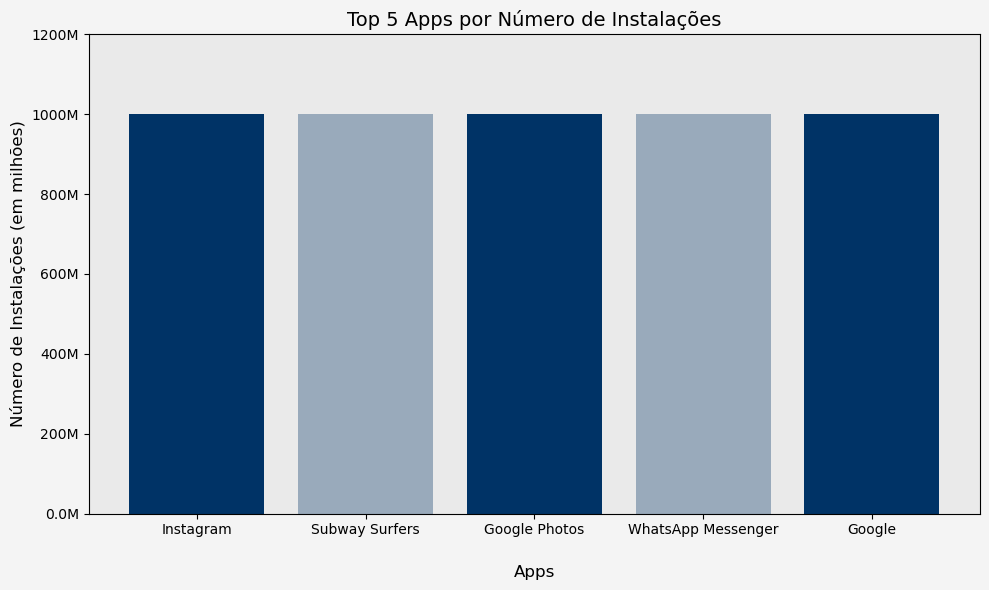

In [4]:
# Garantir que a coluna 'Installs' seja processada corretamente
data['Installs'] = data['Installs'].astype(str).str.replace(",", "").str.replace("+", "")
data['Installs'] = pd.to_numeric(data['Installs'], errors='coerce')  # Converter para numérico
# data['Installs'] = data['Installs'] / 1e6  # Dividir para obter valores em milhões



# Classificar por Installs e Rating
top_5_apps = data.sort_values(by=['Installs', 'Rating','Reviews'], ascending=[False, False,False]).head(5)

# # Exibir os 5 aplicativos mais bem ranqueados
# print("\nTop 5 Apps por Número de Instalações e Rating:")
# print(top_5_apps[['App', 'Installs', 'Rating', 'Reviews']].to_string(index=False))

# Gerar o gráfico
def millions_formatter(x, pos):
    return f'{int(x)}M' if x >= 1 else f'{x:.1f}M'

plt.figure(figsize=(10, 6))

# Cores azul marinho e cinza claro
colors = ['#003366', '#99AABB', '#003366', '#99AABB', '#003366']  # Alternando entre azul marinho e cinza claro

# Plotando as barras
bars = plt.bar(top_5_apps['App'], top_5_apps['Installs'], color=colors)

# Ajustar título, rótulos e eixos
plt.title('Top 5 Apps por Número de Instalações', fontsize=14)
plt.xlabel('Apps', fontsize=12, labelpad=20)
plt.ylabel('Número de Instalações (em milhões)', fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

plt.gca().yaxis.set_major_formatter(FuncFormatter(millions_formatter))

# Ajustar limites no eixo Y
plt.ylim(0, max(top_5_apps['Installs']) * 1.2)

plt.gcf().patch.set_facecolor('#f4f4f4')  # Fundo da figura
plt.gca().set_facecolor('#eaeaea')  # Fundo do gráfico

# Adicionar espaçamento entre as barras no eixo X
plt.tight_layout()
plt.show()




### Conversão de Bilhões para Milhões 
Para facilitar a leitura e a visualização dos dados de instalações dos aplicativos, os valores originais em bilhões foram convertidos para milhões. Isso foi feito dividindo os números por 1 milhão (10^6). Essa transformação torna os números mais gerenciáveis, evitando valores excessivamente grandes e tornando os gráficos mais legíveis e compreensíveis.

### Inclusão do Rating
O rating foi adicionado para resolver empates entre aplicativos com mais de 1 bilhão de instalações. Além disso, o rating possui uma média tanto positiva quanto negativa, o que ajuda a refinar a classificação, considerando tanto a quantidade de instalações quanto a qualidade do aplicativo, medida pelas avaliações dos usuários.

## 2. Gráfico de Pizza das Categorias

Ao criar o gráfico de pizza, percebe-se que, devido ao grande número de categorias, a visualização se torna difícil de entender. Para resolver esse problema, proponho duas soluções:


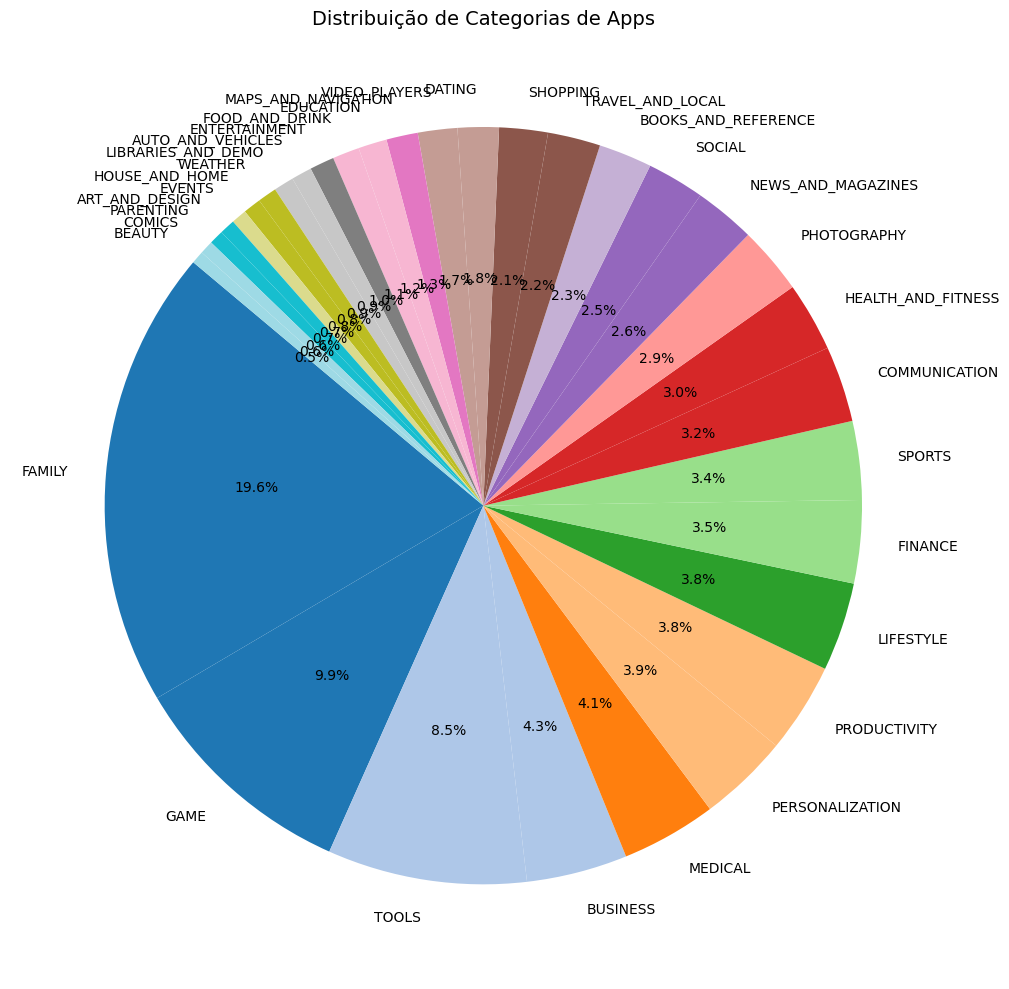

In [5]:
## 2. Gráfico de Pizza das Categorias
# Contando a frequência de categorias
category_counts = data['Category'].value_counts()

# Criando o gráfico de pizza
plt.figure(figsize=(12, 10))  # Aumentando o tamanho do gráfico
category_counts.plot(kind='pie', autopct='%1.1f%%', startangle=140, colormap='tab20')

# Adicionando título e ajustando a visualização
plt.title('Distribuição de Categorias de Apps', fontsize=14)
plt.ylabel('')  # Remover o label do eixo Y
plt.tight_layout()  # Ajuste automático do layout
plt.show()


## Primeira solução
A divisão das categorias foi realizada com o objetivo de simplificar a visualização e a análise. As categorias foram agrupadas de acordo com propósitos semelhantes, facilitando a compreensão e tornando a comparação entre os grupos mais clara. Essa abordagem também permite uma análise mais eficaz do comportamento dos aplicativos.



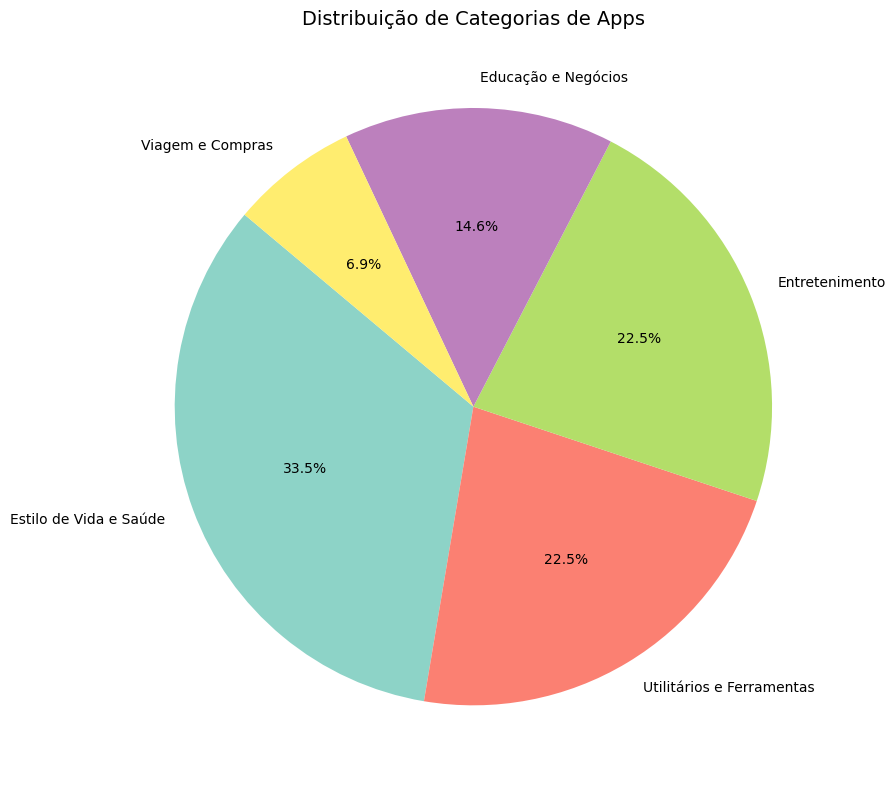

In [6]:
# Agrupando as categorias com uma nova definição
grouped_categories = {
    'Estilo de Vida e Saúde': ['FAMILY', 'LIFESTYLE', 'HEALTH_AND_FITNESS', 'FOOD_AND_DRINK', 'BEAUTY', 'MEDICAL', 'PARENTING', 'HOUSE_AND_HOME'],
    'Entretenimento': ['GAME', 'ENTERTAINMENT', 'PHOTOGRAPHY', 'VIDEO_PLAYERS', 'SOCIAL', 'SPORTS', 'COMICS', 'EVENTS'],
    'Utilitários e Ferramentas': ['TOOLS', 'PRODUCTIVITY', 'PERSONALIZATION', 'COMMUNICATION', 'MAPS_AND_NAVIGATION', 'AUTO_AND_VEHICLES', 'LIBRARIES_AND_DEMO'],
    'Educação e Negócios': ['EDUCATION', 'BUSINESS', 'NEWS_AND_MAGAZINES', 'BOOKS_AND_REFERENCE', 'ART_AND_DESIGN','FINANCE'],
    'Viagem e Compras': ['TRAVEL_AND_LOCAL', 'SHOPPING', 'DATING', 'WEATHER']
}

# Lista de todas as categorias únicas no dataset
all_categories = set(data['Category'].unique())

# Categorias mapeadas no dicionário grouped_categories
mapped_categories = set(category for categories in grouped_categories.values() for category in categories)

# Categorias não mapeadas
unmapped_categories = all_categories - mapped_categories

# # Exibindo categorias não mapeadas
# print("Categorias não mapeadas:", unmapped_categories)

# Caso existam categorias não mapeadas, podemos decidir como agrupá-las
if unmapped_categories:
    # Adicionar as categorias não mapeadas a um grupo apropriado (Exemplo: Utilitários e Ferramentas)
    grouped_categories['Utilitários e Ferramentas'].extend(unmapped_categories)

# Reaplicar a função de categorização com todos os grupos atualizados
def categorize(category):
    for group, categories in grouped_categories.items():
        if category in categories:
            return group
    return 'Não Categorizado'

# Aplicando a categorização
data['Group'] = data['Category'].apply(categorize)

# Contando a frequência das categorias agrupadas
grouped_counts = data['Group'].value_counts()

# # Exibindo o conteúdo atualizado de grouped_counts
# print(grouped_counts)

# Criando o gráfico de pizza com cores vibrantes
plt.figure(figsize=(10, 8))
grouped_counts.plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=140, 
    colormap='Set3'  # Paleta de cores mais vibrante e profissional
)

# Ajustando o título e removendo o rótulo do eixo Y
plt.title('Distribuição de Categorias de Apps', fontsize=14)
plt.ylabel('')  # Remover o label do eixo Y
plt.tight_layout()  # Ajustar layout para evitar cortes

# Mostrar o gráfico
plt.show()


### Explicação sobre a Divisão de Categorias

A divisão das categorias foi feita para simplificar a visualização e análise, agrupando categorias com propósitos semelhantes. Essa abordagem facilita a compreensão, torna a comparação entre os grupos mais clara e permite uma análise mais eficaz do comportamento dos aplicativos.

### 1. **Estilo de Vida e Saúde**
Este grupo inclui categorias relacionadas ao bem-estar e saúde dos usuários, como **FAMILY**, **LIFESTYLE**, **HEALTH_AND_FITNESS**, **FOOD_AND_DRINK**, **BEAUTY**, **MEDICAL**, **PARENTING** e **HOUSE_AND_HOME**. Esses aplicativos visam melhorar a qualidade de vida dos usuários, seja por meio de hábitos saudáveis, cuidados pessoais ou serviços médicos.

### 2. **Entretenimento**
As categorias agrupadas aqui são voltadas para o lazer e socialização, incluindo **GAME**, **ENTERTAINMENT**, **PHOTOGRAPHY**, **VIDEO_PLAYERS**, **SOCIAL**, **SPORTS**, **COMICS** e **EVENTS**. Esses aplicativos proporcionam entretenimento e interação social, como jogos, redes sociais e plataformas de vídeos.

### 3. **Utilitários e Ferramentas**
Este grupo reúne categorias relacionadas à produtividade e utilidade do dia a dia, como **TOOLS**, **PRODUCTIVITY**, **PERSONALIZATION**, **COMMUNICATION**, **MAPS_AND_NAVIGATION**, **AUTO_AND_VEHICLES** e **LIBRARIES_AND_DEMO**. Aplicativos dessa categoria são voltados para facilitar tarefas cotidianas, como comunicação, personalização de dispositivos e navegação.

### 4. **Educação e Negócios**
As categorias **EDUCATION**, **BUSINESS**, **NEWS_AND_MAGAZINES**, **BOOKS_AND_REFERENCE**, **ART_AND_DESIGN** e **FINANCE** estão agrupadas aqui, com foco no aprendizado, aprimoramento profissional e consumo de conteúdo informativo. Esses aplicativos auxiliam na formação acadêmica, desenvolvimento de negócios e busca por conhecimentos especializados.

### 5. **Viagem e Compras**
Este grupo agrupa categorias voltadas para o turismo e o consumo, como **TRAVEL_AND_LOCAL**, **SHOPPING**, **DATING** e **WEATHER**. Esses aplicativos atendem às necessidades de viagens, compras online, serviços de namoro e informações climáticas.


## Segunda solução:
Para uma visualização mais clara e detalhada, onde não é necessário agrupar as categorias, o gráfico ideal seria um **gráfico de barras** (em vez de um gráfico de pizza), especialmente quando há um número elevado de categorias. O gráfico de barras oferece uma forma mais eficiente de comparar categorias com frequências variadas.

### Vantagens do gráfico de barras:
- **Facilidade de leitura**: Ele lida bem com um número grande de categorias, enquanto o gráfico de pizza pode se tornar difícil de interpretar quando há muitas fatias.
- **Comparação precisa**: A altura das barras facilita a comparação das frequências entre as categorias, tornando a análise mais intuitiva.


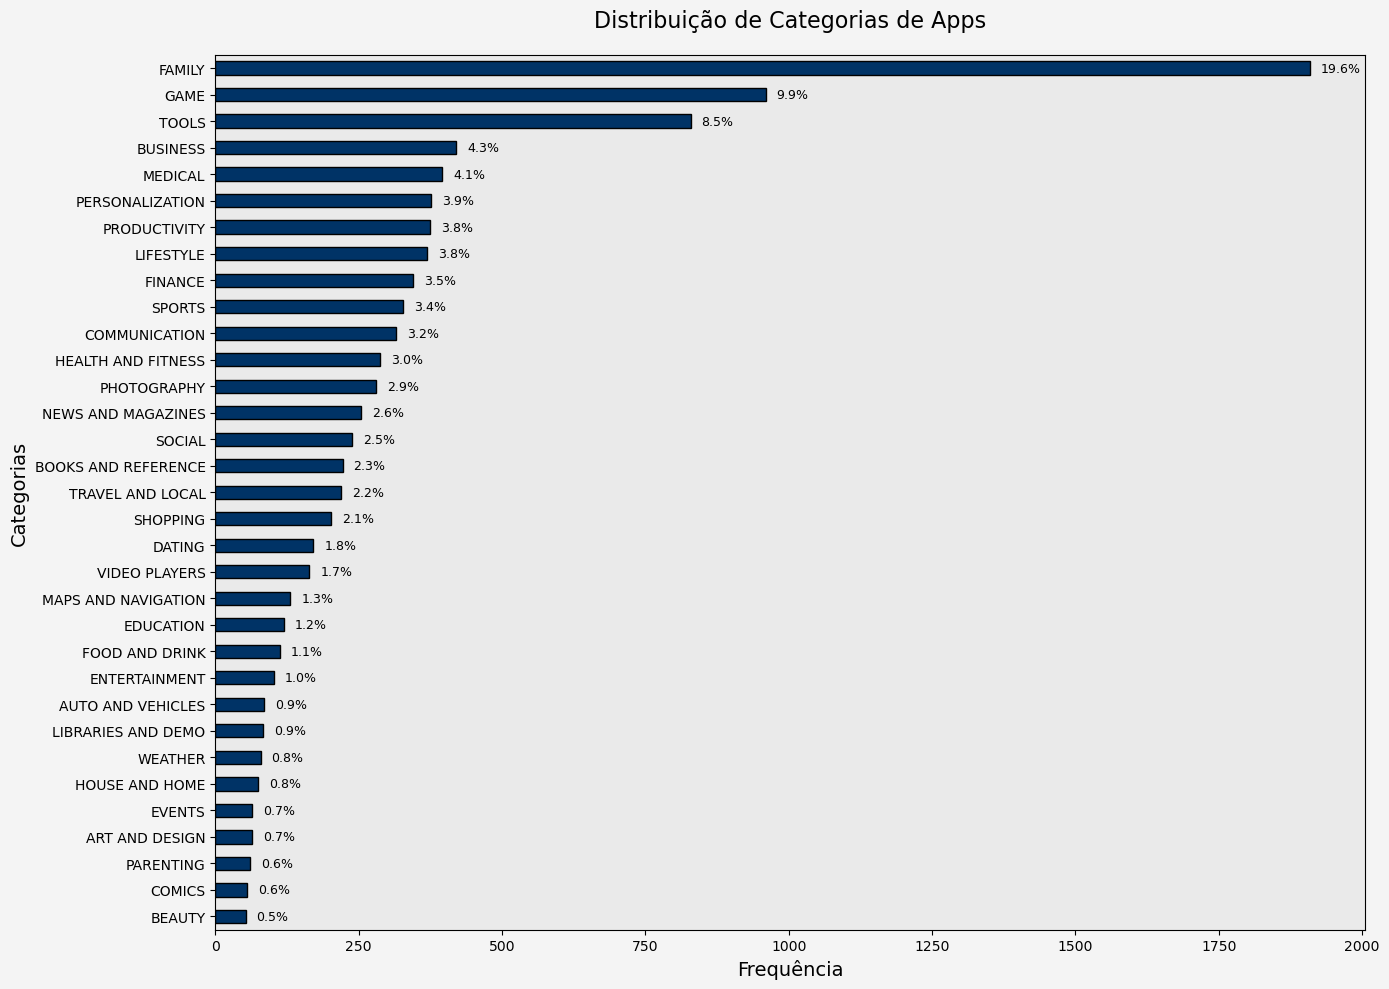

In [7]:
# Contando a frequência de categorias
category_counts = data['Category'].value_counts()

# print("\nFrequência das Categorias Agrupadas:")
# print(category_counts)

# Removendo os underlines das categorias
category_counts.index = category_counts.index.str.replace('_', ' ')

# Ordenando os valores de forma decrescente
category_counts = category_counts.sort_values(ascending=False)

# Calculando as porcentagens
percentage = (category_counts / category_counts.sum()) * 100

# Criando o gráfico de barras horizontal
plt.figure(figsize=(14, 10))  # Figura com dimensões apropriadas

ax = category_counts.plot(kind='barh', color='#003366', edgecolor='black')  # Adicionando borda às barras para destaque

# Adicionando as porcentagens à direita de cada barra
for i, v in enumerate(category_counts):
    ax.text(v + category_counts.max() * 0.01, i, f'{percentage.iloc[i]:.1f}%', va='center', fontsize=9)  # Ajuste dinâmico do deslocamento

# Inverter explicitamente a ordem do eixo Y
ax.invert_yaxis()


# Ajustando título e rótulos
plt.title('Distribuição de Categorias de Apps', fontsize=16, pad=20)  # Pad ajusta o espaçamento do título
plt.xlabel('Frequência', fontsize=14)
plt.ylabel('Categorias', fontsize=14)
# Melhorando o layout
plt.tight_layout()  # Ajusta automaticamente os elementos para evitar sobreposição

# Configurando os fundos
plt.gcf().patch.set_facecolor('#f4f4f4')  # Fundo da figura
ax.set_facecolor('#eaeaea')  # Fundo do gráfico

# # Adicionando grid para melhor leitura (opcional)
# ax.grid(axis='x', linestyle='--', alpha=0.7)

# Exibindo o gráfico
plt.show()

## 3. App Mais Caro

In [8]:
# Remover o '$' e tentar converter para float, substituindo erros por NaN
data['Price'] = data['Price'].replace({r'[$,]': ''}, regex=True)  # Remove '$' e ',' se houver
data['Price'] = pd.to_numeric(data['Price'], errors='coerce')  # Converte para float, com erro como NaN

# Encontrando o aplicativo mais caro
most_expensive_app = data.nlargest(1, 'Price')[['App', 'Price']]

most_expensive_app


,App,Price
5727,I'm Rich - Trump Edition,400.0


## 4 Apps classificados como 'Mature 17+'

In [9]:
# mature_17_plus_count = data[data['Content Rating'] == 'Mature 17+'].shape[0]
# print(f"Número de apps classificados como 'Mature 17+': {mature_17_plus_count}")


mature_17_plus_count = data['Content Rating'].str.contains('Mature 17+', na=False).sum()

print(f"Número de apps classificados como 'Mature 17+': {mature_17_plus_count}")


Número de apps classificados como 'Mature 17+': 393


## 5. Top 10 Apps por Número de Reviews

In [10]:
# Ordenando os dados pela coluna 'Reviews' de forma decrescente
data_sorted = data.sort_values('Reviews', ascending=False)

# Removendo duplicatas, mantendo apenas a linha com o maior número de reviews para cada 'App'
data_unique = data_sorted.drop_duplicates(subset='App', keep='first')

# Selecionando as 10 primeiras aplicações com mais reviews
top10_reviews = data_unique[['App', 'Reviews']].head(10)

# Exibindo as 10 aplicações com mais reviews
top10_reviews




,App,Reviews
0,Facebook,78158306
1,WhatsApp Messenger,69119316
2,Instagram,66577446
3,Messenger Text and Video Chat for Free,56646578
4,Clash of Clans,44893888
6,Clean Master- Space Cleaner Antivirus,42916526
7,Subway Surfers,27725352
8,YouTube,25655305
9,"Security Master - Antivirus, VPN, AppLock, Boo...",24900999
10,Clash Royale,23136735


## 6. Cálculos Adicionais e Gráficos Adicionais

Top 5 Categorias com Mais Aplicativos:
Category
FAMILY      1909
GAME         960
TOOLS        829
BUSINESS     420
MEDICAL      396
Name: count, dtype: int64

Número de Apps por Tipo:
Número de aplicativos pagos ou gratuitos: 9744


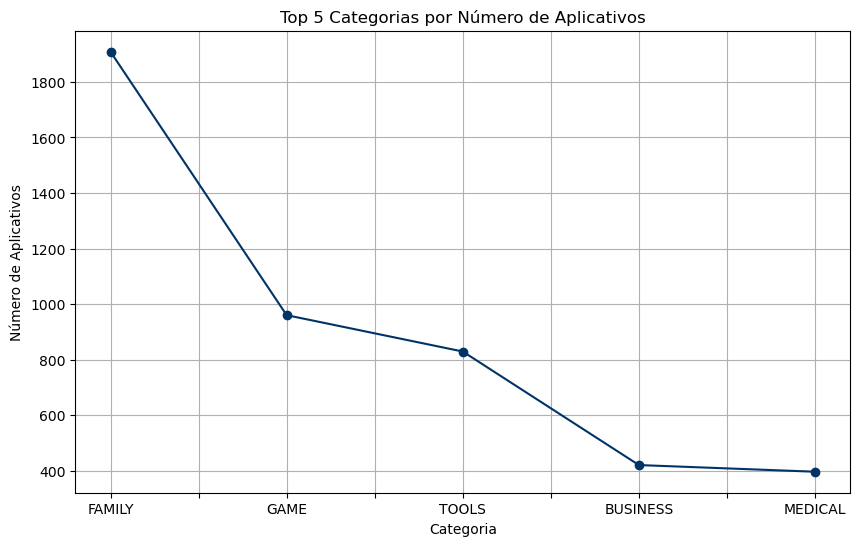

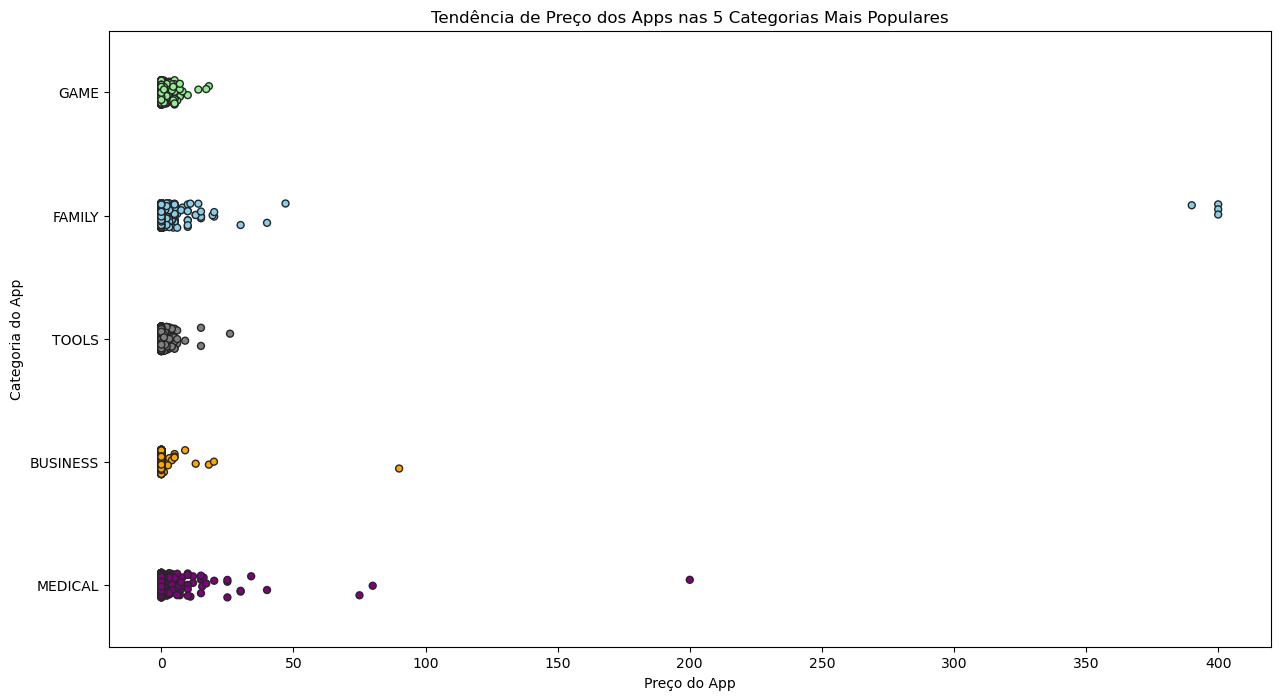

In [11]:
# Cálculo 1: Top 5 Categorias com Mais Aplicativos
top_categories = data['Category'].value_counts().head(5)


# Cálculo 2: Quantidades de Apps por Tipos pago e gratuitos  (Contagem de Aplicativos)
# Filtrando os aplicativos do tipo "Paid" ou "Free"
paid_apps_count = data[(data['Type'] == 'Paid') | (data['Type'] == 'Free')].shape[0]

# Exibindo os resultados no terminal
print("Top 5 Categorias com Mais Aplicativos:")
print(top_categories)
print("\nNúmero de Apps por Tipo:")
print(f"Número de aplicativos pagos ou gratuitos: {paid_apps_count}")

## Gráfico 1: Gráfico de Linha para o Top 5 Categorias por Número de Apps
plt.figure(figsize=(10, 6))
top_categories.plot(kind='line', marker='o', title='Top 5 Categorias por Número de Aplicativos', color='#003366')
plt.xlabel('Categoria')
plt.ylabel('Número de Aplicativos')
plt.xticks()
plt.grid(True)
plt.show()

## Gráfico 2: Gráfico de pontos (stripplot) para Preço de Apps nas 5 Categorias mais Populares

top_5_categorias = ['FAMILY', 'GAME', 'TOOLS', 'BUSINESS', 'MEDICAL']

# Filtrando o dataset para as 5 categorias mais populares
top_5_apps = data[data['Category'].isin(top_5_categorias)]

# Definindo um palete de cores personalizado para cada categoria
custom_palette = {
    'FAMILY': 'skyblue',
    'GAME': 'lightgreen',
    'TOOLS': 'gray',
    'BUSINESS': 'orange',
    'MEDICAL': 'purple'
}

# Criando o gráfico de pontos (stripplot) para preço de apps nas 5 categorias mais populares
fig, ax = plt.subplots(figsize=(15, 8))
ax = sns.stripplot(x='Price', y='Category', hue='Category', data=top_5_apps, 
                   jitter=True, linewidth=1, palette=custom_palette, legend=False)

# Ajustando o título e as labels para refletir a natureza do gráfico
ax.set_title('Tendência de Preço dos Apps nas 5 Categorias Mais Populares')
ax.set_xlabel('Preço do App')
ax.set_ylabel('Categoria do App')

# Exibindo o gráfico
plt.show()